<a href="https://colab.research.google.com/github/AlaaTaima/plant-model/blob/maryam-a/plantmodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import os
base = '/content/drive/MyDrive/plant_project/plantvillage dataset'
print(os.listdir(base))

color = os.path.join(base, 'color')
classes = sorted(os.listdir(color))
print(len(classes), 'classes')
print(classes[:5])

['color', 'grayscale']
38 classes
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [19]:
!ls /content/drive/MyDrive/plant_project

'plantvillage dataset'	 plantvillage-dataset.zip   split.json


In [20]:
from PIL import Image

bad = []
for c in classes:
    folder = os.path.join(color, c)
    for f in os.listdir(folder):
        if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
            bad.append((c, f, 'not an image'))

print('Non-image files:', len(bad))
print(bad[:10])

Non-image files: 0
[]


In [21]:
import random
from PIL import Image

random.seed(42)
corrupt = []
checked = 0

for c in classes:
    folder = os.path.join(color, c)
    files = os.listdir(folder)
    sample = random.sample(files, min(5, len(files)))
    for f in sample:
        path = os.path.join(folder, f)
        try:
            with Image.open(path) as img:
                img.verify()
            checked += 1
        except Exception as e:
            corrupt.append((c, f, str(e)))

print('Checked:', checked)
print('Corrupt:', len(corrupt))
print(corrupt[:10])

Checked: 190
Corrupt: 0
[]


In [22]:
from collections import Counter

sizes = Counter()
for c in classes[:5]:
    folder = os.path.join(color, c)
    for f in os.listdir(folder)[:10]:
        with Image.open(os.path.join(folder, f)) as img:
            sizes[img.size] += 1

print(sizes)

Counter({(256, 256): 50})


In [23]:
# ===== Libraries =====
# System / utilities
import os
import json
import random
from collections import Counter

# Data
import numpy as np
import pandas as pd
from PIL import Image

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Split / balancing / evaluation
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# Reproducibility: نفس النتايج عند كل الفريق
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [24]:
paths, labels = [], []

for idx, c in enumerate(classes):
    folder = os.path.join(color, c)
    for f in os.listdir(folder):
        paths.append(os.path.join(folder, f))
        labels.append(idx)

print('Total images:', len(paths))
print('Total labels:', len(labels))
print('Example:', paths[0], '->', classes[labels[0]])

Total images: 54305
Total labels: 54305
Example: /content/drive/MyDrive/plant_project/plantvillage dataset/color/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG -> Apple___Apple_scab


In [25]:
train_p, temp_p, train_l, temp_l = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)

val_p, test_p, val_l, test_l = train_test_split(
    temp_p, temp_l, test_size=0.50, stratify=temp_l, random_state=SEED)

print('Train:', len(train_p), '| Val:', len(val_p), '| Test:', len(test_p))

Train: 38013 | Val: 8146 | Test: 8146


In [26]:
def dist(lbls):
    c = Counter(lbls)
    return [c[i] for i in range(len(classes))]

df = pd.DataFrame({
    'class': classes,
    'train': dist(train_l),
    'val': dist(val_l),
    'test': dist(test_l),
})
print(df.to_string())


                                                 class  train  val  test
0                                   Apple___Apple_scab    441   95    94
1                                    Apple___Black_rot    435   93    93
2                             Apple___Cedar_apple_rust    193   41    41
3                                      Apple___healthy   1152  247   246
4                                  Blueberry___healthy   1051  225   226
5             Cherry_(including_sour)___Powdery_mildew    736  158   158
6                    Cherry_(including_sour)___healthy    598  128   128
7   Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    359   77    77
8                          Corn_(maize)___Common_rust_    834  179   179
9                  Corn_(maize)___Northern_Leaf_Blight    690  148   147
10                              Corn_(maize)___healthy    813  175   174
11                                   Grape___Black_rot    826  177   177
12                        Grape___Esca_(Black_Measl

In [27]:
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(classes)),
    y=np.array(train_l)
)
class_weight = dict(enumerate(weights))

# اعرضي أكبر وأصغر weights
for i in np.argsort(weights)[[0, 1, -2, -1]]:
    print(f'{classes[i]}: {weights[i]:.2f}')

Orange___Haunglongbing_(Citrus_greening): 0.26
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 0.27
Apple___Cedar_apple_rust: 5.18
Potato___healthy: 9.44


In [28]:
split_path = '/content/drive/MyDrive/plant_project/split.json'
if not os.path.exists(split_path):
    with open(split_path, 'w') as f:
        json.dump(split, f)
    print('Saved split.json')
else:
    print('split.json already exists, skipped')

split.json already exists, skipped


In [29]:
with open('/content/drive/MyDrive/plant_project/split.json') as f:
    s = json.load(f)
print(len(s['train']['paths']), len(s['val']['paths']), len(s['test']['paths']))

38013 8146 8146


In [30]:
IMG_SIZE = 224
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

augment = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
])

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_img, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_p, train_l, training=True)
val_ds   = make_ds(val_p, val_l)
test_ds  = make_ds(test_p, test_l)

In [31]:
for x, y in train_ds.take(1):
    print(x.shape, y.shape, x.numpy().min(), x.numpy().max())

(32, 224, 224, 3) (32,) -123.68 131.03458


In [32]:
base_model = ResNet50(weights='imagenet', include_top=False,
                      input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(classes), activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │        77,862 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,665,574 (90.28 MB)

 Trainable params: 77,862 (304.15 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [33]:
SAVE_PATH = '/content/drive/MyDrive/plant_project/resnet50_best.keras'

cbs = [
    callbacks.ModelCheckpoint(SAVE_PATH, monitor='val_accuracy',
                              save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_loss', patience=3,
                            restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2),
]
print('Callbacks ready')

Callbacks ready


In [34]:
import time
t = time.time()
model.fit(train_ds.take(20), validation_data=val_ds.take(10), epochs=1)
print('Seconds:', round(time.time() - t))

20/20 ━━━━━━━━━━━━━━━━━━━━ 137s 5s/step - accuracy: 0.1969 - loss: 3.3826 - val_accuracy: 0.4469 - val_loss: 2.3486
Seconds: 137


In [35]:
!cp "/content/drive/MyDrive/plant_project/plantvillage-dataset.zip" /content/
!unzip -q /content/plantvillage-dataset.zip -d /content/data
!ls /content/data

'plantvillage dataset'


In [36]:
OLD = '/content/drive/MyDrive/plant_project/plantvillage dataset'
NEW = '/content/data/plantvillage dataset'

# اتأكدي الأول إن المسار الجديد صح
print(os.listdir(NEW))
print(len(os.listdir(os.path.join(NEW, 'color'))), 'classes')

def remap(ps):
    return [p.replace(OLD, NEW) for p in ps]

train_p2, val_p2, test_p2 = remap(train_p), remap(val_p), remap(test_p)

# تأكدي إن الملفات موجودة فعلًا
print(all(os.path.exists(p) for p in train_p2[:200]))
print(train_p2[0])

['grayscale', 'color', 'segmented']
38 classes
True
/content/data/plantvillage dataset/color/Apple___Cedar_apple_rust/5ba35826-8831-4638-a443-5c28f80c4de8___FREC_C.Rust 0212.JPG


In [37]:
train_ds = make_ds(train_p2, train_l, training=True)
val_ds   = make_ds(val_p2, val_l)
test_ds  = make_ds(test_p2, test_l)

In [38]:
import time
t = time.time()
model.fit(train_ds.take(20), validation_data=val_ds.take(10), epochs=1)
print('Seconds:', round(time.time() - t))

20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 588ms/step - accuracy: 0.4609 - loss: 2.0868 - val_accuracy: 0.5938 - val_loss: 1.5226
Seconds: 12


In [40]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weight,
    callbacks=cbs
)

Epoch 1/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.9600 - loss: 0.1234
Epoch 1: val_accuracy improved from 0.94243 to 0.94869, saving model to /content/drive/MyDrive/plant_project/resnet50_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/plant_project/resnet50_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 625s 526ms/step - accuracy: 0.9594 - loss: 0.1275 - val_accuracy: 0.9487 - val_loss: 0.1476 - learning_rate: 3.0000e-04
Epoch 2/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.9593 - loss: 0.1290
Epoch 2: val_accuracy did not improve from 0.94869
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 607s 511ms/step - accuracy: 0.9595 - loss: 0.1302 - val_accuracy: 0.9473 - val_loss: 0.1555 - learning_rate: 3.0000e-04
Epoch 3/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 490ms/step - accuracy: 0.9610 - loss: 0.1192
Epoch 3: val_accuracy improved from 0.94869 to 0.95360, saving model to /content/drive/MyDrive/plant_project/resnet50_best.keras

Epoch 3: finished saving mode

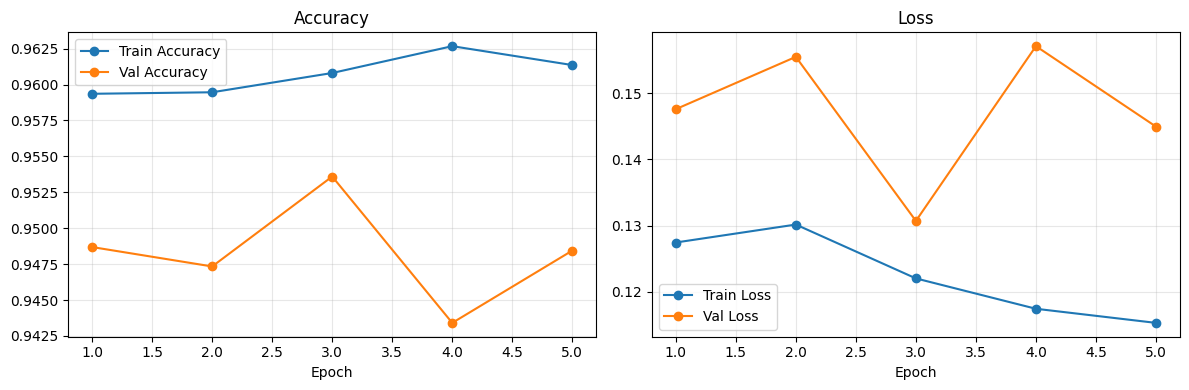

Final Train Acc: 0.9614 | Val Acc: 0.9484
Final Train Loss: 0.1153 | Val Loss: 0.1449
Gap (train - val acc): 0.0129


In [41]:
acc,  val_acc  = history.history['accuracy'], history.history['val_accuracy']
loss, val_loss = history.history['loss'],     history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'o-', label='Train Accuracy')
plt.plot(epochs_range, val_acc, 'o-', label='Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'o-', label='Train Loss')
plt.plot(epochs_range, val_loss, 'o-', label='Val Loss')
plt.title('Loss')
plt.xlabel('Epoch'); plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/plant_project/resnet50_curves.png', dpi=150)
plt.show()

print(f'Final Train Acc: {acc[-1]:.4f} | Val Acc: {val_acc[-1]:.4f}')
print(f'Final Train Loss: {loss[-1]:.4f} | Val Loss: {val_loss[-1]:.4f}')
print(f'Gap (train - val acc): {acc[-1] - val_acc[-1]:.4f}')

In [42]:
test_loss, test_acc = model.evaluate(test_ds)
print(f'Test Accuracy: {test_acc:.4f}')

y_true = np.array(test_l)
y_pred = np.argmax(model.predict(test_ds), axis=1)

print('Macro F1:', round(f1_score(y_true, y_pred, average='macro'), 4))
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

255/255 ━━━━━━━━━━━━━━━━━━━━ 28s 107ms/step - accuracy: 0.9575 - loss: 0.1276
Test Accuracy: 0.9575
255/255 ━━━━━━━━━━━━━━━━━━━━ 33s 110ms/step
Macro F1: 0.9517
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.912     0.989     0.949        94
                                 Apple___Black_rot      1.000     0.968     0.984        93
                          Apple___Cedar_apple_rust      1.000     0.976     0.988        41
                                   Apple___healthy      0.980     1.000     0.990       246
                               Blueberry___healthy      1.000     1.000     1.000       226
          Cherry_(including_sour)___Powdery_mildew      1.000     0.968     0.984       158
                 Cherry_(including_sour)___healthy      1.000     0.984     0.992       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.731     0.987     0.840        77
          

In [43]:
model.save('/content/drive/MyDrive/plant_project/resnet50_final.keras')
print('Saved')

Saved


In [44]:
with open('/content/drive/MyDrive/plant_project/classes.json', 'w') as f:
    json.dump(classes, f)
print('Saved classes.json')

Saved classes.json
